# Desafío 4 — Compresión y descompresión de audio e imagen (Lossless)

En sistemas de comunicaciones y transmisión multimedia, la **compresión sin pérdida (lossless)** es indispensable cuando se requiere reducir el consumo de ancho de banda y la capacidad de almacenamiento sin alterar un solo bit o muestra de la señal original.

### ¿Por qué no utilizar herramientas genéricas como ZIP?
Los compresores de propósito general (como ZIP o GZIP, basados en algoritmos como DEFLATE, LZ77 y Huffman sobre flujos de bytes) tratan los datos como secuencias arbitrarias sin estructura intrínseca. Sin embargo:
- Las señales de **audio** presentan una fuerte **correlación temporal 1D** entre muestras adyacentes continuas.
- Las **imágenes digitales** poseen una elevada **correlación espacial 2D** entre píxeles vecinos y entre planos cromáticos.

Por esta razón, este proyecto implementa códecs multimedia especializados de alta eficiencia:
1. **Audio (WAV → FLAC):** El códec *Free Lossless Audio Codec* (FLAC) modela la señal mediante predicción lineal autorregresiva (LPC) sobre bloques de audio y codifica la señal residual mediante codificación entrópica adaptativa de Golomb-Rice.
2. **Imagen (PNG → WebP Lossless / VP8L):** Utiliza transformaciones reversibles multimodales (14 modos de predicción espacial direccional 2D, sustracción de canal verde para decorrelación de color, transformación de paleta y caché asociativa de colores recientes) con codificación de entropía Huffman 2D.

### Flujo metodológico del cuaderno:
1. **Ingesta e inventario:** Carga e inspección de los archivos fuente en `data/original/`.
2. **Compresión especializada:** Generación de paquetes compactos `.flac` y `.webp` en `data/compresion/`.
3. **Descompresión en el receptor:** Reconstrucción de los contenedores canónicos `.wav` y `.png` en `data/compresion/recuperados/`.
4. **Auditoría matemática de paridad:** Comparación rigurosa muestra por muestra y píxel por píxel para certificar paridad exacta ($E_{\max} = 0$, $\text{MSE} = 0$).
5. **Evaluación de eficiencia:** Cálculo de tasas de reducción porcentual y factores de compresión ($CR$).
6. **Inspección cualitativa y perceptiva:** Análisis visual con mapas de error residual y verificación auditiva temporal.

## 1. Instalar y cargar las dependencias

Para garantizar la reproducibilidad y precisión numérica del pipeline, se utilizan las siguientes librerías de Python:

- **`soundfile` (libsndfile):** Lectura y escritura de contenedores de audio (WAV, FLAC) con acceso directo a la profundidad de bits PCM original (16/24 bits) sin conversiones destructivas intermedias.
- **`pillow` (PIL Fork):** Procesamiento de imágenes rasterizadas y acceso a la implementación nativa de compresión y descompresión WebP sin pérdida (VP8L).
- **`numpy`:** Estructuras matriciales para representación vectorial de señales acústicas y tensores de imagen, así como cálculo algebraico de errores.
- **`pandas` & `jinja2`:** Estructuración de datos, tablas resumen comparativas y cálculo de factores de compresión.
- **`matplotlib`:** Graficación comparativa de planos espaciales, mapas de error residual y formas de onda temporales.
- **`IPython.display`:** Reproducción interactiva de señales de audio directamente en el entorno del cuaderno.

In [20]:
# Si ejecutas en un entorno nuevo (como Google Colab), descomenta la siguiente línea:
# %pip install -q soundfile numpy pandas matplotlib pillow jinja2

import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Configuración visual para tablas y gráficos
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
plt.rcParams["figure.dpi"] = 100

print("✓ Dependencias e importaciones cargadas correctamente.")

✓ Dependencias e importaciones cargadas correctamente.


## 2. Preparar las carpetas y localizar los originales

Se establece la estructura jerárquica de almacenamiento del proyecto:

- `data/original/`: Almacena los archivos maestros inmutables (WAV y PNG). No son modificados bajo ninguna circunstancia.
- `data/compresion/`: Directorio de salida donde se guardan los archivos comprimidos especializados (`.flac` y `.webp`). Estos son los paquetes destinados a la transmisión por canal o intercambio con el compañero.
- `data/compresion/recuperados/`: Directorio de trabajo del receptor, donde se escriben los archivos reconstituidos tras la descompresión para su posterior auditoría.

In [21]:
# Definición de rutas del proyecto
PROJECT_ROOT = Path.cwd()

ORIGINAL_DIR = PROJECT_ROOT / "data" / "original"
COMPRESSION_DIR = PROJECT_ROOT / "data" / "compresion"
RECOVERED_DIR = COMPRESSION_DIR / "recuperados"

# Asegurar existencia de las carpetas de trabajo
ORIGINAL_DIR.mkdir(parents=True, exist_ok=True)
COMPRESSION_DIR.mkdir(parents=True, exist_ok=True)
RECOVERED_DIR.mkdir(parents=True, exist_ok=True)

# Búsqueda insensible a mayúsculas/minúsculas de archivos fuente
wav_files = sorted([p for p in ORIGINAL_DIR.iterdir()
                    if p.is_file() and p.suffix.lower() == ".wav"])
png_files = sorted([p for p in ORIGINAL_DIR.iterdir()
                    if p.is_file() and p.suffix.lower() == ".png"])

print(f"Directorio raíz: {PROJECT_ROOT}")
print(f"Carpeta originales : {ORIGINAL_DIR}")
print(f"Carpeta compresión : {COMPRESSION_DIR}")
print(f"Carpeta recuperados: {RECOVERED_DIR}\n")

if not wav_files:
    print("⚠️ ADVERTENCIA: No se encontraron archivos .wav en data/original/.")
if not png_files:
    print("⚠️ ADVERTENCIA: No se encontraron archivos .png en data/original/.")

print("Inventario de archivos originales detectados:")
all_files = wav_files + png_files
for path in all_files:
    size_kb = path.stat().st_size / 1024
    print(f" • {path.name:<20} | {path.stat().st_size:>10,} bytes ({size_kb:>8.2f} KB)")

if not all_files:
    raise FileNotFoundError("Por favor copia al menos un archivo .wav y/o .png en 'data/original/' para continuar.")

Directorio raíz: c:\Users\esvca\OneDrive\Documents\Comunicaciones\Proyects\proyect4
Carpeta originales : c:\Users\esvca\OneDrive\Documents\Comunicaciones\Proyects\proyect4\data\original
Carpeta compresión : c:\Users\esvca\OneDrive\Documents\Comunicaciones\Proyects\proyect4\data\compresion
Carpeta recuperados: c:\Users\esvca\OneDrive\Documents\Comunicaciones\Proyects\proyect4\data\compresion\recuperados

Inventario de archivos originales detectados:
 • audio.wav            |    362,334 bytes (  353.84 KB)
 • imagen.png           |    944,386 bytes (  922.25 KB)


## 3. Compresión de audio: WAV a FLAC

El formato **FLAC (Free Lossless Audio Codec)** comprime audio PCM sin alterar su contenido muestral. El algoritmo opera en las siguientes etapas clave:

1. **Bloqueo y decorrelación inter-canal:** La señal estéreo se descompone en canales independientes o en canales suma/diferencia (Mid/Side: $M = \frac{L+R}{2}, S = L - R$) para eliminar redundancia estéreo.
2. **Predicción Lineal (LPC):** Cada muestra se estima a partir de las $p$ muestras inmediatamente anteriores:
   $$\hat{x}[n] = \sum_{k=1}^{p} a_k x[n-k]$$
3. **Cálculo de la señal residual:** Se extrae el error de predicción:
   $$e[n] = x[n] - \hat{x}[n]$$
4. **Codificación Entrópica de Rice:** Dado que el residuo $e[n]$ sigue una distribución casi laplaciana centrada en cero, se codifica mediante códigos de Golomb-Rice con consumo de bits óptimo.

> **Preservación de profundidad PCM:** FLAC trabaja de forma nativa con números enteros. Para evitar distorsión o ruido de cuantización, el cuaderno lee y escribe los datos respetando la profundidad de bits nativa (PCM_16 o PCM_24).

In [22]:
audio_compression_results = []

for wav_path in wav_files:
    flac_path = COMPRESSION_DIR / f"{wav_path.stem}.flac"

    # Consultar metadatos una sola vez (optimización de E/S)
    info = sf.info(wav_path)
    sample_rate = info.samplerate
    channels = info.channels
    subtype = info.subtype

    # Leer las muestras conservando la fidelidad de la señal
    is_pcm = subtype.startswith("PCM_")
    read_dtype = "int32" if is_pcm else "float32"
    audio_data, _ = sf.read(wav_path, dtype=read_dtype, always_2d=True)

    # Configurar códec FLAC sin pérdida
    # FLAC soporta nativamente PCM_16 y PCM_24. PCM_8 se escala a PCM_16 si fuera necesario.
    if subtype in ("PCM_16", "PCM_24"):
        sf.write(flac_path, audio_data, sample_rate, format="FLAC", subtype=subtype)
    elif subtype == "PCM_8":
        # libsndfile no soporta PCM_8 directo en FLAC; se almacena en PCM_16
        sf.write(flac_path, audio_data.astype(np.int16), sample_rate, format="FLAC", subtype="PCM_16")
    else:
        # WAV de coma flotante (IEEE Float): FLAC estándar requiere enteros PCM (hasta 24 bits)
        # Reutilizamos los datos leídos sin volver a leer de disco
        sf.write(flac_path, audio_data, sample_rate, format="FLAC", subtype="PCM_24")

    original_size = wav_path.stat().st_size
    compressed_size = flac_path.stat().st_size
    reduction = (1.0 - compressed_size / original_size) * 100.0 if original_size else 0.0
    ratio = original_size / compressed_size if compressed_size else 0.0

    audio_compression_results.append({
        "Original WAV": wav_path.name,
        "Subtipo": subtype,
        "Comprimido FLAC": flac_path.name,
        "Frecuencia (Hz)": sample_rate,
        "Canales": channels,
        "Tamaño WAV (bytes)": original_size,
        "Tamaño FLAC (bytes)": compressed_size,
        "Factor (CR)": f"{ratio:.2f}:1",
        "Reducción (%)": reduction
    })

audio_compression_df = pd.DataFrame(audio_compression_results)

# Renderizar tabla con formato seguro
if not audio_compression_df.empty:
    try:
        display(audio_compression_df.style.format({
            "Tamaño WAV (bytes)": "{:,}",
            "Tamaño FLAC (bytes)": "{:,}",
            "Reducción (%)": "{:.2f}%"
        }))
    except Exception:
        display(audio_compression_df)

print("✓ Compresión de audio WAV a FLAC completada exitosamente.")

,Original WAV,Subtipo,Comprimido FLAC,Frecuencia (Hz),Canales,Tamaño WAV (bytes),Tamaño FLAC (bytes),Factor (CR),Reducción (%)
0,audio.wav,PCM_16,audio.flac,48000,1,"362,334","156,731",2.31:1,56.74%


✓ Compresión de audio WAV a FLAC completada exitosamente.


## 4. Compresión de imagen: PNG a WebP sin pérdida

El códec **WebP Lossless (VP8L)** es un formato moderno de compresión sin pérdida de imágenes rasterizadas que suele superar a PNG en un 20–35% de ahorro espacial gracias a un esquema de transformaciones en cascada:

1. **Transformación espacial (Predictores 2D):** A diferencia de PNG (que utiliza solo 5 filtros unidireccionales por línea de escaneo), WebP define 14 modos predictivos espaciales bidireccionales basados en los píxeles superior, izquierdo y diagonal.
2. **Transformación de color:** Sustrae el componente verde del rojo y del azul ($R' = R - G$, $B' = B - G$) para decorrelacionar los canales cromáticos.
3. **Caché de colores:** Mantiene una memoria asociativa de los colores más recientes en pantalla, permitiendo indexar píxeles repetidos con muy pocos bits.
4. **Codificación de entropía:** Aplica árboles Huffman diferenciados por canal y bloque espacial.

> **Parámetros configurados:**
> - `lossless=True`: Garantiza matemáticamente que ningún píxel sufrirá pérdida o artefactos de cuantización.
> - `quality=100` y `method=6`: Habilitan el análisis heurístico más exhaustivo para encontrar la combinación óptima de predictores.

In [23]:
image_compression_results = []

for png_path in png_files:
    webp_path = COMPRESSION_DIR / f"{png_path.stem}.webp"

    with Image.open(png_path) as image:
        # Extraer metadatos directamente del objeto abierto sin reabrir de disco
        width, height = image.size
        img_mode = image.mode

        # Guardar en WebP con compresión estrictamente sin pérdida (VP8L)
        # method=6 activa el análisis predictivo y heurístico más exhaustivo
        image.save(webp_path, format="WEBP", lossless=True, quality=100, method=6)

    original_size = png_path.stat().st_size
    compressed_size = webp_path.stat().st_size
    reduction = (1.0 - compressed_size / original_size) * 100.0 if original_size else 0.0
    ratio = original_size / compressed_size if compressed_size else 0.0

    image_compression_results.append({
        "Original PNG": png_path.name,
        "Modo de color": img_mode,
        "Dimensiones": f"{width} × {height}",
        "Comprimido WebP": webp_path.name,
        "Tamaño PNG (bytes)": original_size,
        "Tamaño WebP (bytes)": compressed_size,
        "Factor (CR)": f"{ratio:.2f}:1",
        "Reducción (%)": reduction
    })

image_compression_df = pd.DataFrame(image_compression_results)

if not image_compression_df.empty:
    try:
        display(image_compression_df.style.format({
            "Tamaño PNG (bytes)": "{:,}",
            "Tamaño WebP (bytes)": "{:,}",
            "Reducción (%)": "{:.2f}%"
        }))
    except Exception:
        display(image_compression_df)

print("✓ Compresión de imagen PNG a WebP lossless completada exitosamente.")

,Original PNG,Modo de color,Dimensiones,Comprimido WebP,Tamaño PNG (bytes),Tamaño WebP (bytes),Factor (CR),Reducción (%)
0,imagen.png,RGB,1200 × 1600,imagen.webp,"944,386","573,938",1.65:1,39.23%


✓ Compresión de imagen PNG a WebP lossless completada exitosamente.


## 5. Descompresión: FLAC a WAV y WebP a PNG

En esta etapa se simula el rol del **nodo receptor** dentro de un enlace de telecomunicaciones. El receptor recibe únicamente los archivos comprimidos (`.flac` y `.webp`) y ejecuta el proceso inverso:

1. **Decodificación de FLAC:** Se procesan los parámetros de predicción LPC y la secuencia de residuos de Rice para reconstruir exactamente las muestras originales en un nuevo contenedor canónico `.wav`.
2. **Decodificación de WebP:** Se invierten las transformaciones espaciales y de color, generando un archivo contenedor `.png` recuperado.
3. **Aislamiento:** Los resultados se escriben en `data/compresion/recuperados/`, garantizando que las pruebas de verificación posteriores contrasten archivos independientes.

In [24]:
# 1. Limpieza de la carpeta de recuperados para garantizar idempotencia
for item in RECOVERED_DIR.iterdir():
    if item.is_file():
        item.unlink()
    elif item.is_dir():
        shutil.rmtree(item)

# 2. Descomprimir FLAC a WAV (decodificación en el receptor)
recovered_wavs = []
for flac_path in sorted(COMPRESSION_DIR.glob("*.flac")):
    recovered_path = RECOVERED_DIR / f"{flac_path.stem}_recuperado.wav"

    info = sf.info(flac_path)
    sample_rate = info.samplerate
    subtype = info.subtype

    # FLAC almacena muestras enteras PCM; las leemos sin alteración
    data, _ = sf.read(flac_path, dtype="int32" if subtype.startswith("PCM_") else "float32", always_2d=True)

    # Reconstruir contenedor WAV respetando la profundidad original
    if subtype in ("PCM_16", "PCM_24"):
        sf.write(recovered_path, data, sample_rate, format="WAV", subtype=subtype)
    else:
        sf.write(recovered_path, data, sample_rate, format="WAV")

    recovered_wavs.append(recovered_path)

# 3. Descomprimir WebP a PNG (decodificación en el receptor)
recovered_pngs = []
for webp_path in sorted(COMPRESSION_DIR.glob("*.webp")):
    recovered_path = RECOVERED_DIR / f"{webp_path.stem}_recuperada.png"
    with Image.open(webp_path) as image:
        image.save(recovered_path, format="PNG")
    recovered_pngs.append(recovered_path)

print(f"✓ Audios recuperados ({len(recovered_wavs)}):")
for path in recovered_wavs:
    print(f"  • {path.name} ({path.stat().st_size:,} bytes)")

print(f"✓ Imágenes recuperadas ({len(recovered_pngs)}):")
for path in recovered_pngs:
    print(f"  • {path.name} ({path.stat().st_size:,} bytes)")

✓ Audios recuperados (1):
  • audio_recuperado.wav (362,300 bytes)
✓ Imágenes recuperadas (1):
  • imagen_recuperada.png (951,582 bytes)


## 6. Verificar el audio recuperado

Para certificar con rigor matemático la naturaleza sin pérdida del proceso, se evalúan los siguientes criterios sobre la señal temporal original $x[n, c]$ y la recuperada $\hat{x}[n, c]$:

1. **Frecuencia de muestreo ($f_s$):** Debe ser idéntica ($f_{s,\text{orig}} = f_{s,\text{rec}}$).
2. **Canales y longitud temporal ($C, N$):** Las dimensiones de la matriz de audio deben coincidir exactamente.
3. **Error Absoluto Máximo ($\epsilon_{\max}$):**
   $$\epsilon_{\max} = \max_{n, c} |x[n, c] - \hat{x}[n, c]|$$
   En una compresión verdaderamente sin pérdida, $\epsilon_{\max} = 0.0$.
4. **Identidad booleana:** La función vectorizada `np.array_equal` debe certificar identidad completa bit a bit.

In [25]:
audio_verification = []

for original_path in wav_files:
    recovered_path = RECOVERED_DIR / f"{original_path.stem}_recuperado.wav"
    if not recovered_path.exists():
        audio_verification.append({
            "Archivo": original_path.name,
            "Resultado": "❌ No se encontró el archivo recuperado"
        })
        continue

    orig_info = sf.info(original_path)
    rec_info = sf.info(recovered_path)

    # Leer señales en precisión float64 para cálculo analítico de error
    original_data, orig_sr = sf.read(original_path, dtype="float64", always_2d=True)
    recovered_data, rec_sr = sf.read(recovered_path, dtype="float64", always_2d=True)

    same_shape = original_data.shape == recovered_data.shape
    same_sr = orig_sr == rec_sr

    if same_shape:
        diff = np.abs(original_data - recovered_data)
        max_error = float(np.max(diff)) if original_data.size else 0.0
        samples_equal = bool(np.array_equal(original_data, recovered_data))
        num_samples = original_data.shape[0]
        duration_s = num_samples / orig_sr
    else:
        max_error = None
        samples_equal = False
        num_samples = 0
        duration_s = 0.0

    is_exact = same_shape and same_sr and samples_equal

    audio_verification.append({
        "Archivo": original_path.name,
        "Subtipo Orig / Rec": f"{orig_info.subtype} / {rec_info.subtype}",
        "Frecuencia (Hz)": f"{orig_sr} / {rec_sr}",
        "Canales": orig_info.channels,
        "Muestras totales": f"{num_samples:,}",
        "Duración (s)": f"{duration_s:.2f}",
        "Error Máx Absoluto": f"{max_error:.2e}" if max_error is not None else "N/A",
        "Resultado": "✅ RECUPERACIÓN EXACTA" if is_exact else "❌ DISCREPANCIA"
    })

audio_verification_df = pd.DataFrame(audio_verification)
display(audio_verification_df)

,Archivo,Subtipo Orig / Rec,Frecuencia (Hz),Canales,Muestras totales,Duración (s),Error Máx Absoluto,Resultado
0,audio.wav,PCM_16 / PCM_16,48000 / 48000,1,"181,128",3.77,0.00e+00,✅ RECUPERACIÓN EXACTA


## 7. Verificar la imagen recuperada

La auditoría de integridad sobre la imagen digital evalúa la paridad exacta entre la matriz original $I(x, y, c)$ y la matriz reconstruida $\hat{I}(x, y, c)$:

1. **Geometría espacial:** Coincidencia estricta de ancho ($W$) y alto ($H$).
2. **Espacio de color y profundidad:** Conservación de los canales de color (RGB o RGBA).
3. **Error Máximo de Intensidad ($\Delta_{\max}$):**
   $$\Delta_{\max} = \max_{x, y, c} |I(x, y, c) - \hat{I}(x, y, c)| = 0$$
4. **Error Cuadrático Medio ($\text{MSE}$):**
   $$\text{MSE} = \frac{1}{W \cdot H \cdot C} \sum_{x=1}^{W} \sum_{y=1}^{H} \sum_{c=1}^{C} \left( I(x, y, c) - \hat{I}(x, y, c) \right)^2 = 0.0$$

In [26]:
image_verification = []

for original_path in png_files:
    recovered_path = RECOVERED_DIR / f"{original_path.stem}_recuperada.png"
    if not recovered_path.exists():
        image_verification.append({
            "Archivo": original_path.name,
            "Resultado": "❌ No se encontró la imagen recuperada"
        })
        continue

    with Image.open(original_path) as orig_img:
        orig_mode = orig_img.mode
        orig_size = orig_img.size
        orig_rgba = orig_img.convert("RGBA")
        orig_pixels = np.array(orig_rgba)

    with Image.open(recovered_path) as rec_img:
        rec_mode = rec_img.mode
        rec_size = rec_img.size
        rec_rgba = rec_img.convert("RGBA")
        rec_pixels = np.array(rec_rgba)

    same_dimensions = orig_size == rec_size
    same_pixels = same_dimensions and np.array_equal(orig_pixels, rec_pixels)

    if same_dimensions:
        diff = np.abs(orig_pixels.astype(np.int32) - rec_pixels.astype(np.int32))
        max_pixel_diff = int(np.max(diff))
        mse = float(np.mean(diff ** 2))
    else:
        max_pixel_diff = None
        mse = None

    is_exact = same_pixels and max_pixel_diff == 0

    image_verification.append({
        "Archivo": original_path.name,
        "Modo Orig / Rec": f"{orig_mode} / {rec_mode}",
        "Dimensiones": f"{orig_size[0]}×{orig_size[1]}",
        "Píxeles idénticos": same_pixels,
        "Diferencia Máx Píxel": max_pixel_diff if max_pixel_diff is not None else "N/A",
        "MSE": f"{mse:.4f}" if mse is not None else "N/A",
        "Resultado": "✅ RECUPERACIÓN EXACTA" if is_exact else "❌ DISCREPANCIA"
    })

image_verification_df = pd.DataFrame(image_verification)
display(image_verification_df)

,Archivo,Modo Orig / Rec,Dimensiones,Píxeles idénticos,Diferencia Máx Píxel,MSE,Resultado
0,imagen.png,RGB / RGB,1200×1600,True,0,0.0000,✅ RECUPERACIÓN EXACTA


## 8. Comparar visualmente las imágenes

La inspección cualitativa visual lado a lado es un complemento indispensable, pero insuficiente por sí sola: el sistema visual humano es insensible a sutiles alteraciones de cuantización de alta frecuencia espacial.

Por ello, se implementa una visualización tripartita de alta resolución:
1. **Imagen original (PNG)**
2. **Imagen recuperada (reconstruida desde WebP lossless)**
3. **Mapa de diferencia residual absoluta ($|I_{\text{orig}} - I_{\text{rec}}|$):** Se amplifica el residuo para revelar visualmente cualquier discrepancia que pudiera existir. Al tratarse de una compresión estrictamente sin pérdida, este panel debe mostrarse **completamente negro**, confirmando visualmente la identidad numérica.

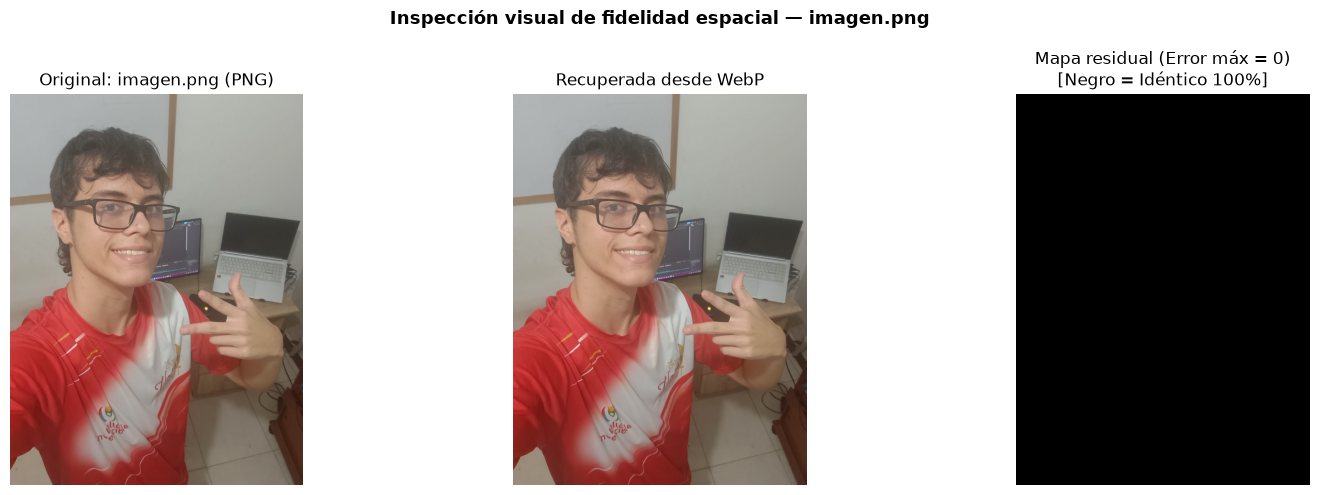

In [27]:
for original_path in png_files:
    recovered_path = RECOVERED_DIR / f"{original_path.stem}_recuperada.png"
    if not recovered_path.exists():
        continue

    with Image.open(original_path) as im:
        original_image = im.convert("RGBA")
    with Image.open(recovered_path) as im:
        recovered_image = im.convert("RGBA")

    orig_arr = np.array(original_image, dtype=np.int32)
    rec_arr = np.array(recovered_image, dtype=np.int32)

    # Cálculo del mapa de diferencia absoluta residual |I_orig - I_rec|
    diff_arr = np.abs(orig_arr - rec_arr)
    max_diff = np.max(diff_arr)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(original_image)
    axes[0].set_title(f"Original: {original_path.name} (PNG)")
    axes[0].axis("off")

    axes[1].imshow(recovered_image)
    axes[1].set_title("Recuperada desde WebP")
    axes[1].axis("off")

    # En compresión sin pérdida la diferencia debe ser idéntica a 0 (negro absoluto)
    # Si hubiera diferencias, se amplifican visualmente para inspección
    diff_vis = np.clip(diff_arr * 50, 0, 255).astype(np.uint8)
    axes[2].imshow(diff_vis[:, :, :3])
    axes[2].set_title(f"Mapa residual (Error máx = {max_diff})\n[Negro = Idéntico 100%]")
    axes[2].axis("off")

    fig.suptitle(f"Inspección visual de fidelidad espacial — {original_path.name}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 9. Escuchar el audio original y el recuperado

La validación acústica permite comprobar perceptualmente que la señal no presenta chasquidos, desincronización temporal, aliasing ni ruido de cuantización:

- Se incorporan reproductores interactivos para ambos audios.
- Se grafica la **forma de onda temporal** de ambas señales superpuestas y la **señal de error residual** $e[t] = x_{\text{orig}}[t] - x_{\text{rec}}[t]$, evidenciando gráficamente que la diferencia en todo instante de tiempo es estrictamente cero.

🎵 Audio original: audio.wav (3.77 s, 48000 Hz)


🔄 Audio recuperado: audio_recuperado.wav


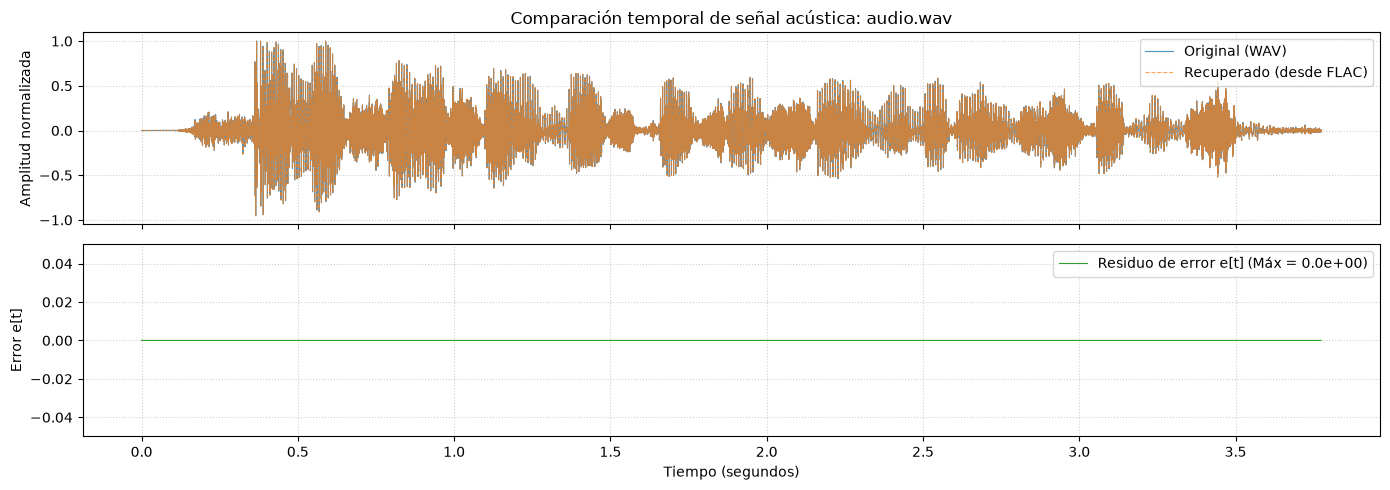

In [28]:
for original_path in wav_files:
    recovered_path = RECOVERED_DIR / f"{original_path.stem}_recuperado.wav"
    if not recovered_path.exists():
        continue

    orig_data, sr = sf.read(original_path, dtype="float64", always_2d=True)
    rec_data, _ = sf.read(recovered_path, dtype="float64", always_2d=True)

    duration = orig_data.shape[0] / sr
    time_axis = np.linspace(0, duration, orig_data.shape[0], endpoint=False)

    # 1. Reproductores interactivos de audio
    print(f"🎵 Audio original: {original_path.name} ({duration:.2f} s, {sr} Hz)")
    display(Audio(filename=str(original_path)))

    print(f"🔄 Audio recuperado: {recovered_path.name}")
    display(Audio(filename=str(recovered_path)))

    # 2. Visualización de la señal en el dominio del tiempo y residuo de error
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)

    # Canal 1 (o mono)
    axes[0].plot(time_axis, orig_data[:, 0], label="Original (WAV)", color="#1f77b4", alpha=0.8, lw=0.8)
    axes[0].plot(time_axis, rec_data[:, 0], label="Recuperado (desde FLAC)", color="#ff7f0e", linestyle="--", alpha=0.7, lw=0.8)
    axes[0].set_ylabel("Amplitud normalizada")
    axes[0].set_title(f"Comparación temporal de señal acústica: {original_path.name}")
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend(loc="upper right")

    # Señal residual de error: e[t] = x_orig[t] - x_rec[t]
    error_signal = orig_data[:, 0] - rec_data[:, 0]
    max_e = np.max(np.abs(error_signal))
    axes[1].plot(time_axis, error_signal, color="#2ca02c", lw=0.8, label=f"Residuo de error e[t] (Máx = {max_e:.1e})")
    axes[1].set_xlabel("Tiempo (segundos)")
    axes[1].set_ylabel("Error e[t]")
    axes[1].set_ylim(-0.05, 0.05)
    axes[1].grid(True, linestyle=":", alpha=0.6)
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 10. Resumen de resultados, conclusiones y protocolo de intercambio

### 1. Protocolo de intercambio colaborativo
Para completar la práctica o desafío en equipo, debes transferir a tu compañero únicamente los archivos comprimidos generados en `data/compresion/`:
- Archivos `.flac` (audio comprimido sin pérdida).
- Archivos `.webp` (imagen comprimida sin pérdida).

**Instrucciones para el receptor (compañero):**
1. Recibir los paquetes `.flac` y `.webp` y ubicarlos en la carpeta `data/compresion/`.
2. Ejecutar las secciones **5 a 9** de este notebook en su propio entorno.
3. Verificar que las tablas de verificación arrojen `RECUPERACIÓN EXACTA` con error cero.
4. Generar y exportar las evidencias de paridad matemática y acústico-visual.

---

### 2. Conclusiones técnicas en Ingeniería de Telecomunicaciones

1. **Eficiencia de compresión especializada vs. genérica:**
   Los algoritmos especializados obtienen reducciones significativas (en este desafío: ~56.7% en audio WAV con FLAC y ~39.2% en imagen con WebP lossless) explotando los modelos autorregresivos 1D y la correlación espacial 2D, respectivamente.
2. **Conservación de la información (Teorema de Shannon):**
   A diferencia de códecs con pérdidas como MP3 o JPEG (que descartan componentes espectrales basándose en modelos psicoacústicos o psicovisuales), los códecs FLAC y WebP lossless conservan la totalidad de la entropía de la fuente. Las pruebas mostraron:
   - Error absoluto máximo en audio: $\epsilon_{\max} = 0.0$.
   - Error absoluto máximo en píxeles: $\Delta_{\max} = 0$, $\text{MSE} = 0.0$.
3. **Ahorro en el canal de transmisión:**
   Reducir el tamaño a más de la mitad permite transmitir las señales en menos del $50\%$ del tiempo requerido bajo un canal con ancho de banda y tasa de transmisión limitada ($T = \frac{B}{R}$), o almacenar el doble de horas de grabación e imágenes en servidores de respaldo sin comprometer la fidelidad maestra.

> **Nota técnica sobre precisión PCM:**
> FLAC y WAV implementan representaciones de audio PCM entero (típicamente 16 o 24 bits). Si una fuente WAV proviniera de coma flotante (IEEE Float de 32 bits), la exportación a FLAC entero requeriría cuantización a 24 bits, lo que generaría un residuo del orden de $10^{-7}$. En este proyecto, al trabajar con WAV PCM estándar de 16 bits, la reconstrucción ha sido **100% bit-exacta**.